In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

%matplotlib inline

pd.set_option('display.max_columns', None)

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\jenim\.cache\kagglehub\datasets\asaniczka\uk-optimal-product-price-prediction\versions\3


In [3]:
data = pd.read_csv(r'C:\Users\jenim\Desktop\DSML\Week2\D5\amz_uk_price_prediction_dataset.csv')

In [5]:
df = data.copy()

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [7]:
display(df)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [8]:
num = df.select_dtypes(include='number')
cat = df.select_dtypes(exclude='number')

In [9]:
num

,uid,stars,reviews,price,boughtInLastMonth
0,1,4.7,15308,21.99,0
1,2,4.7,98099,23.99,0
2,3,4.7,15308,21.99,0
3,4,4.7,7205,31.99,0
4,5,4.6,1881,17.99,0
...,...,...,...,...,...
2443646,2828589,0.0,0,22.34,0
2443647,2828590,0.0,0,97.99,0
2443648,2828591,0.0,0,52.99,0
2443649,2828592,4.3,404,79.99,0


In [10]:
cat

,asin,title,isBestSeller,category
0,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",False,Hi-Fi Speakers
1,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",True,Hi-Fi Speakers
2,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",False,Hi-Fi Speakers
3,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",False,Hi-Fi Speakers
4,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,False,Hi-Fi Speakers
...,...,...,...,...
2443646,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",False,Motorbike Clothing
2443647,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,False,Motorbike Clothing
2443648,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,False,Motorbike Clothing
2443649,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,False,Motorbike Clothing


Part 1: Analyzing Best-Seller Trends Across Product Categories
Objective: Understand the relationship between product categories and their best-seller status.

Crosstab Analysis:

Create a crosstab between the product category and the isBestSeller status.

Are there categories where being a best-seller is more prevalent?

Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.

In [95]:
cat.columns

Index(['asin', 'title', 'isBestSeller', 'category'], dtype='object')

In [11]:
crosstab = pd.crosstab(cat.category, cat.isBestSeller)
crosstab

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [12]:
ct= crosstab.sort_values(True, ascending=False)
ct

isBestSeller,False,True
category,,
Grocery,9008,556
Health & Personal Care,9017,552
Baby,14709,341
Sports & Outdoors,835935,330
Power & Hand Tools,8353,306
...,...,...
Downhill Ski Boots,1284,0
Digital Frames,774,0
Motorbike Chassis,107,0


In [98]:
proportion= cat.isBestSeller.value_counts(normalize=True)
proportion

isBestSeller
False    0.996734
True     0.003266
Name: proportion, dtype: float64

In [13]:
ct.proportion_Bsellers = ((ct[True])/(ct[True] + ct[False]))
round(ct.proportion_Bsellers.sort_values(ascending=False), 4)

C:\Users\jenim\AppData\Local\Temp\ipykernel_21508\1564168358.py:1: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  ct.proportion_Bsellers = ((ct[True])/(ct[True] + ct[False]))


category
Grocery                                    0.0581
Smart Home Security & Lighting             0.0577
Health & Personal Care                     0.0577
Mobile Phone Accessories                   0.0425
Power & Hand Tools                         0.0353
                                            ...  
Vases                                      0.0000
Blank Media Cases & Wallets                0.0000
Bedding Collections                        0.0000
Internal TV Tuner & Video Capture Cards    0.0000
eBook Readers & Accessories                0.0000
Length: 296, dtype: float64

Statistical Tests:

1. Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
2. Compute Cramér's V to understand the strength of association between best-seller status and category.

In [14]:
from scipy.stats import chi2_contingency

In [15]:
from scipy.stats.contingency import association

In [16]:
_, chi_pivalue, _, _ = chi2_contingency(crosstab)
float(chi_pivalue)

0.0

In [17]:
association(crosstab, method='cramer')

0.1222829439760564

Visualizations:

Visualize the relationship between product categories and the best-seller status using a stacked bar chart

In [18]:
top20 = ct.sort_values(True, ascending=False).head(20)
top20

isBestSeller,False,True
category,,
Grocery,9008,556
Health & Personal Care,9017,552
Baby,14709,341
Sports & Outdoors,835935,330
Power & Hand Tools,8353,306
Beauty,19010,302
Pet Supplies,9152,285
Arts & Crafts,9319,230
Women,17559,213


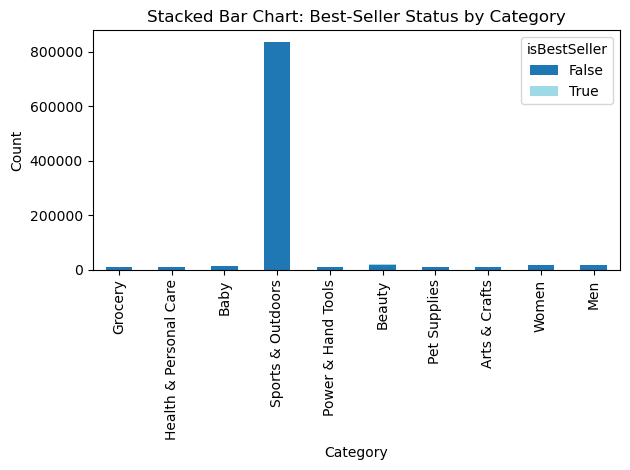

In [134]:
top10.plot(kind='bar', stacked=True, colormap='tab20')

plt.title("Stacked Bar Chart: Best-Seller Status by Category")
plt.xlabel("Category")
plt.ylabel("Count")
plt.legend(title="isBestSeller")
plt.tight_layout()
plt.show()

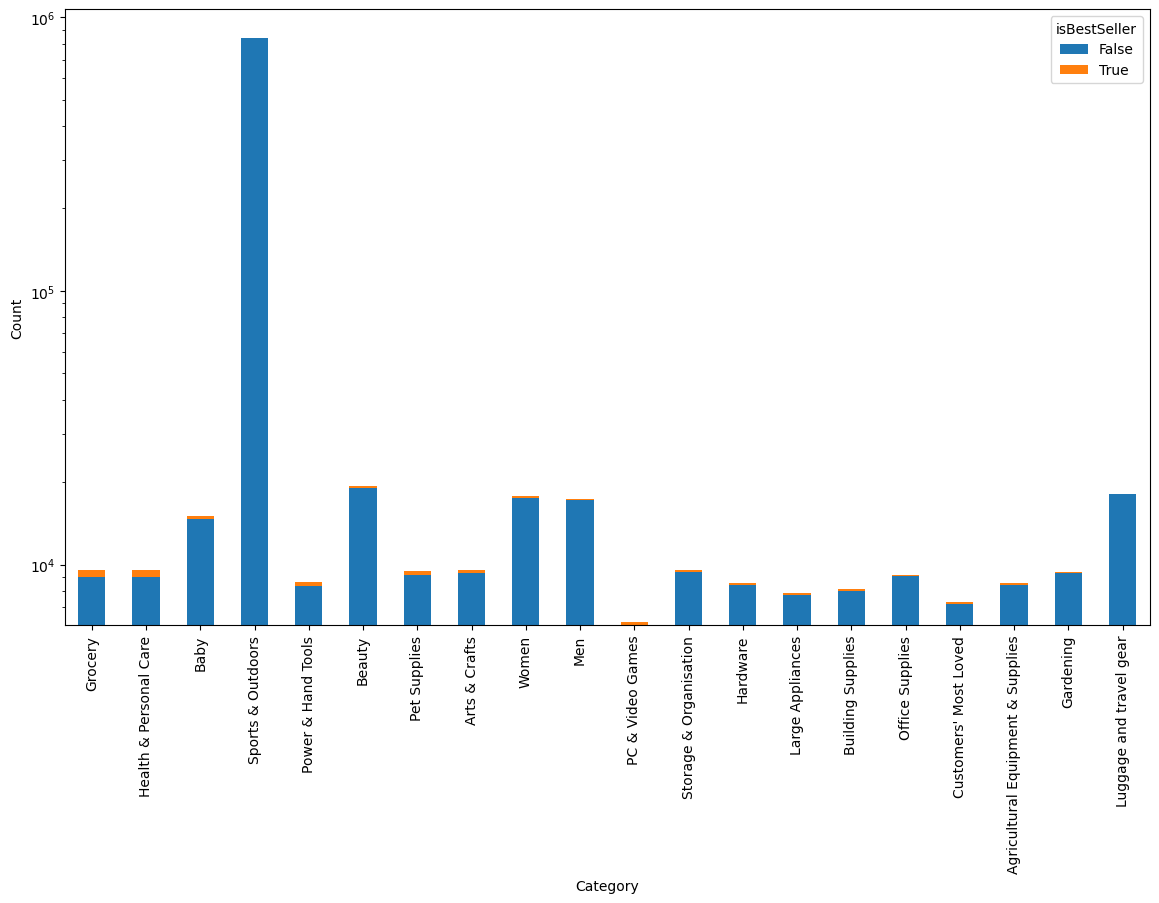

In [19]:
top20.plot(kind='bar', stacked=True, figsize=(14,8), log=True)
plt.xlabel('Category')
plt.ylabel('Count')
plt.legend(title="isBestSeller")
plt.show()

Insight: 
1. The sports and outdoor category is the largest category.
2. Most categories have maximum non Best sellers compared to a very few Best sellers.


Part 2: Exploring Product Prices and Ratings Across Categories and Brands
Objective: Investigate how different product categories influence product prices.

Preliminary Step: Remove outliers in product prices.

For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.

Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.

In [20]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [21]:
Q1=df.price.quantile(0.25)
Q3= df.price.quantile(0.75)
IRQ = Q3 - Q1
IRQ

np.float64(36.0)

In [22]:
lower_limit=Q1 - 1.5*IRQ
upper_limit = Q3+ 1.5 *IRQ

In [23]:
df_no_outliers= df[(df.price >= lower_limit) & (df.price <= upper_limit)]

In [24]:
df.shape

(2443651, 9)

In [25]:
df_no_outliers.shape

(2115963, 9)

Violin Plots:

Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.
Which product category tends to have the highest median price? Don't filter here by top categories.


In [26]:
top20_categories = df_no_outliers.category.value_counts().head(20).index
top20_categories

Index(['Sports & Outdoors', 'Beauty', 'Bath & Body',
       'Manicure & Pedicure Products',
       'Handmade Clothing, Shoes & Accessories', 'Make-up', 'Skin Care',
       'Hair Care', 'Birthday Gifts', 'Handmade Gifts', 'Handmade Home Décor',
       'Luggage and travel gear', 'Women', 'Fragrances',
       'Handmade Kitchen & Dining', 'Handmade Artwork',
       'Handmade Home & Kitchen Products', 'Handmade Jewellery', 'Men',
       'Baby'],
      dtype='object', name='category')

In [ ]:
df_top20= df_no_outliers[df_no_outliers.category.isin(top20_categories)]

C:\Users\jenim\AppData\Local\Temp\ipykernel_21508\926906369.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_top20, x='category', y='price', inner='quartile',palette="coolwarm")


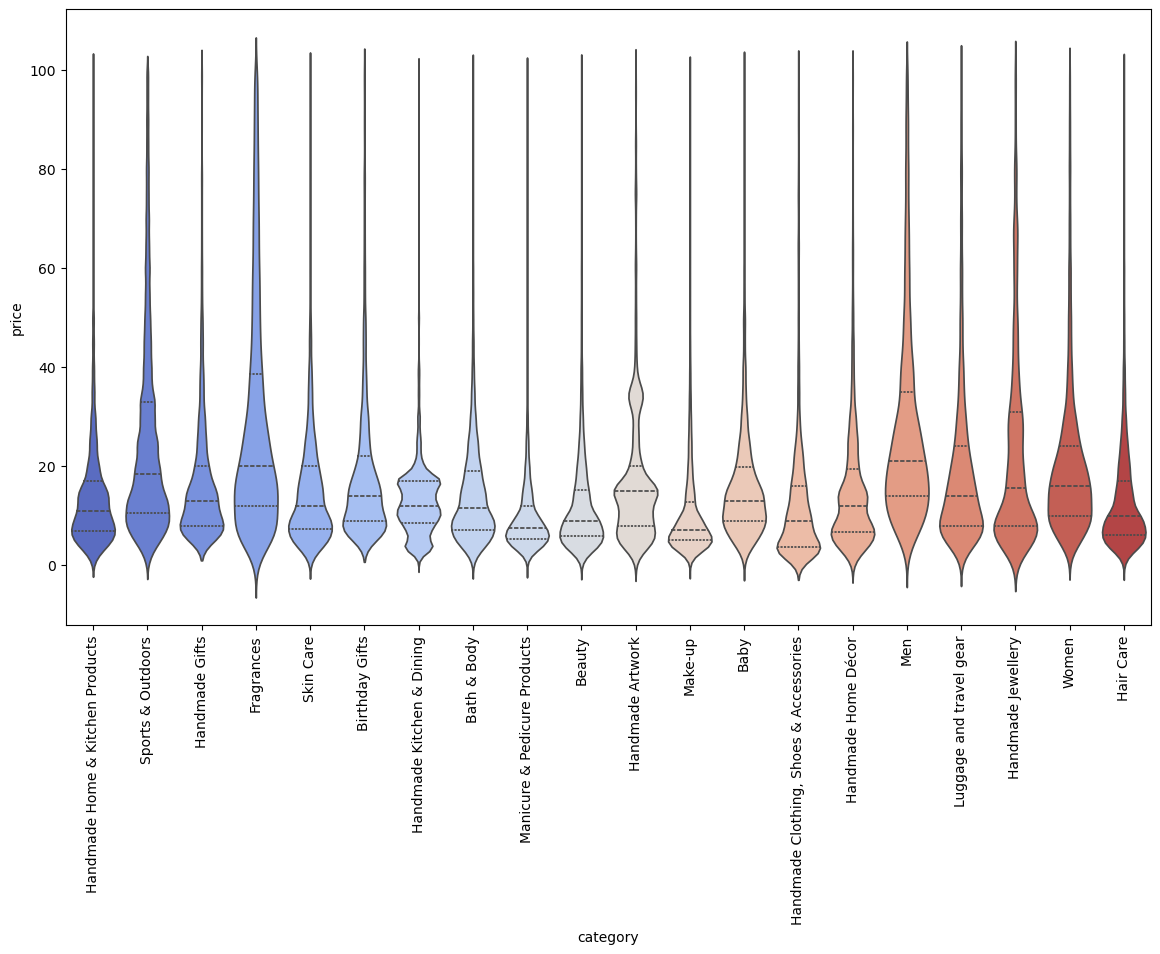

In [28]:
plt.figure(figsize=(14,8))
sns.violinplot(data=df_top20, x='category', y='price', inner='quartile',palette="coolwarm")
plt.xticks(rotation=90)
plt.show()

Insight: This plot shows clear distribution in price across categories. the plot highlights that product pricing is strongly influenced by category type, with handmade and specialty items tending to be more expensive.

In [47]:
median_price = df_no_outliers.groupby('category')['price'].median().sort_values(ascending=False)
median_price

category
Desktop PCs              74.00
Boxing Shoes             69.79
Tablets                  69.00
Graphics Cards           68.54
Motherboards             67.92
                         ...  
Adapters                  7.05
Make-up                   7.00
Signs & Plaques           6.99
Arts & Crafts             5.99
Office Paper Products     4.37
Name: price, Length: 296, dtype: float64

In [48]:
print(f'The product category with high median price is {median_price.head(1)}')

The product category with high median price is category
Desktop PCs    74.0
Name: price, dtype: float64


2. Bar Charts:

Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
Which product category commands the highest average price? Don't filter here by top categories.

In [56]:
frequency= cat.category.value_counts()
frequency

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [57]:
top10_categories = frequency.head(10).index
top10_categories

Index(['Sports & Outdoors', 'Beauty', 'Handmade Clothing, Shoes & Accessories',
       'Bath & Body', 'Birthday Gifts', 'Manicure & Pedicure Products',
       'Skin Care', 'Make-up', 'Hair Care', 'Fragrances'],
      dtype='object', name='category')

In [63]:
top10 = df_no_outliers[df_no_outliers.category.isin(top10_categories)]
average = top10.groupby('category')['price'].mean().sort_values(ascending=False)
average


category
Fragrances                                28.544912
Sports & Outdoors                         25.172065
Birthday Gifts                            18.600195
Skin Care                                 15.654722
Bath & Body                               14.678683
Hair Care                                 13.461408
Handmade Clothing, Shoes & Accessories    12.958639
Beauty                                    12.523480
Make-up                                   10.612918
Manicure & Pedicure Products              10.231825
Name: price, dtype: float64

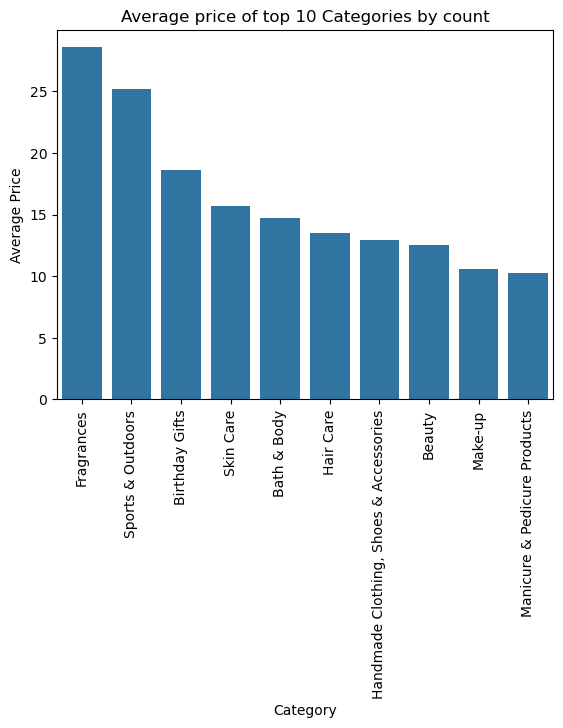

In [80]:
sns.barplot(x=average.index, y=average.values)
plt.title('Average price of top 10 Categories by count')
plt.xlabel('Category')
plt.ylabel('Average Price')
plt.xticks(rotation=90)
plt.show()

In [69]:
average_price = df_no_outliers.groupby('category')['price'].mean().sort_values(ascending=False)
average_price

category
Motherboards             68.772432
Boxing Shoes             67.417803
Desktop PCs              66.915562
Tablets                  66.552971
Graphics Cards           65.103509
                           ...    
Bedding Accessories       8.835220
Adapters                  8.750197
Signs & Plaques           8.210513
Arts & Crafts             8.006540
Office Paper Products     6.876369
Name: price, Length: 296, dtype: float64

In [70]:
print(f'The product category with high median price is {average_price.head(1)}')

The product category with high median price is category
Motherboards    68.772432
Name: price, dtype: float64


3. Box Plots:

Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

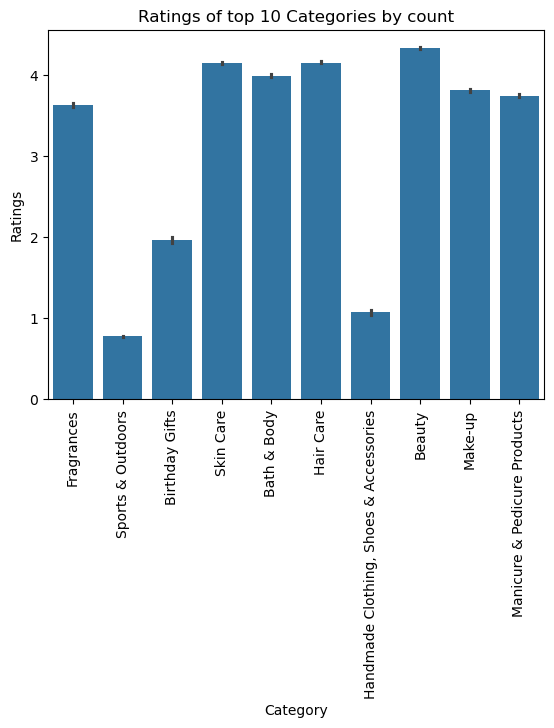

In [83]:
sns.barplot(x='category', y='stars', data=top10, order=average.index)
plt.title('Ratings of top 10 Categories by count')
plt.xlabel('Category')
plt.ylabel('Ratings')
plt.xticks(rotation=90)
plt.show()

In [86]:
median_rating = df_no_outliers.groupby('category')['stars'].median().sort_values(ascending=False)
median_rating

category
Computer Memory                 4.7
Building & Construction Toys    4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Kids' Play Figures              4.6
                               ... 
Hockey Shoes                    0.0
Hi-Fi Receivers & Separates     0.0
Handmade Kitchen & Dining       0.0
Handmade Jewellery              0.0
eBook Readers & Accessories     0.0
Name: stars, Length: 296, dtype: float64

In [87]:
print(f'The product category with high median rating is {median_rating.head(1)}')

The product category with high median rating is category
Computer Memory    4.7
Name: stars, dtype: float64


Part 3: Investigating the Interplay Between Product Prices and Ratings
Objective: Analyze how product ratings (stars) correlate with product prices.

1. Correlation Coefficients:

Calculate the correlation coefficient between price and stars.
Is there a significant correlation between product price and its rating?


In [ ]:
price_stars = df_no_outliers.groupby('price')

Pearson correlation

In [90]:
round(float(df_no_outliers.price.corr(df_no_outliers.stars)), 2)


-0.08

Spearman correlation

In [92]:
round(float(df_no_outliers.price.corr(df_no_outliers.stars, method='spearman')), 2)


-0.07

Insights:
1. Possibility 1: Both Pearson and Spearman have negative correlations indicating that as the price tends to increase, rating tends to decrease.
2. Possibility 2: As both correlations are are very close to 0, they suggest a weak or no correlation between price and ratings.

2. Visualizations:

Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
Use a correlation heatmap to visualize correlations between all numerical variables.
Examine if product prices typically follow a normal distribution using a QQ plot.

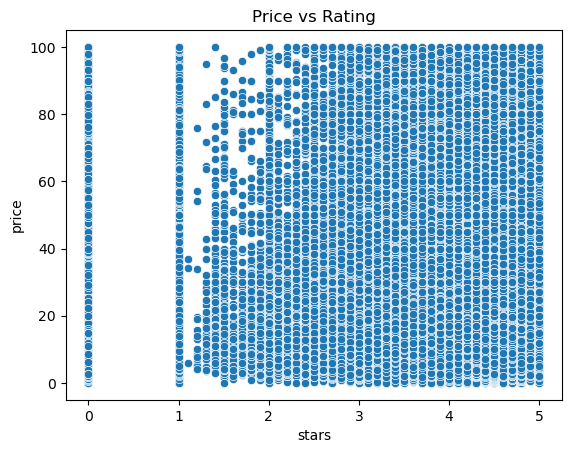

In [96]:
sns.scatterplot(x='stars', y='price', data=df_no_outliers)
plt.title('Price vs Rating')
plt.show()

Observation: No real pattern observed other than that ratings are clustered around 3-5 stars rating.

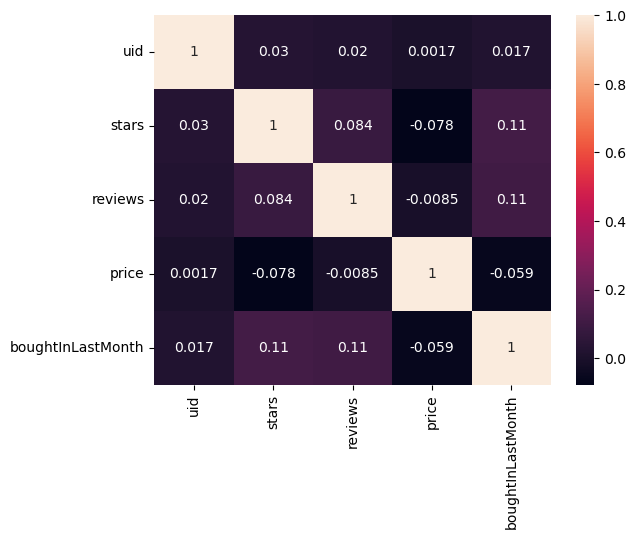

In [99]:
num2=df_no_outliers.select_dtypes(include='number')
sns.heatmap(num2.corr(), annot=True)
plt.show()

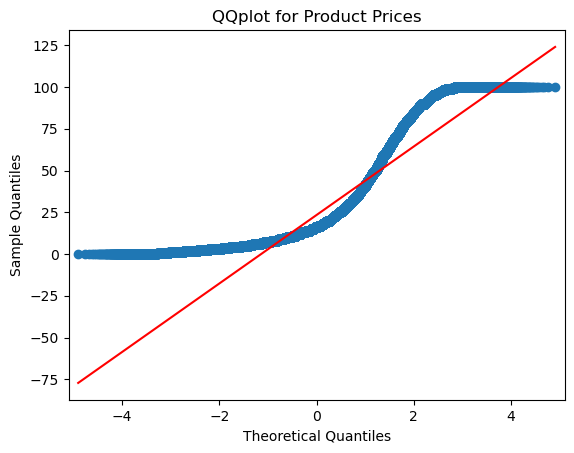

In [104]:
import statsmodels.api as sm
sm.qqplot(df_no_outliers.price, line='s')
plt.title('QQplot for Product Prices')
plt.show()